# 01 · The platform's grid and the 30 m shares

**Questions:** which cells make the platform's 100 m grid? Does the 100 m grid give the right forest and loss area, and would 50 m, 10 m or hexagons do better?

Hansen's pixels are 30 m (0.09 ha). The module puts them on a coarser grid, and three ways of doing so are compared:

| Way | What a cell holds | Used by |
|---|---|---|
| **One value per cell** | One canopy value and one loss year, as Earth Engine reads them at 100 m by default; the whole cell counts as forest, and as lost | The deforestation notebook of the methodology document |
| **Majority** | Forest, or lost in a year, if over half of its 30 m pixels are; the whole cell counts | A common way to make a coarse map |
| **Per-cell share** | The share of its 30 m pixels that are forest and that were lost in each year; the area is the share times the cell area | Proposed |

The truth is the area of Hansen's own 30 m pixels: canopy above 30 % in 2000, and loss in each year 2013–2024. It comes from the stage-1 count of every 30 m pixel (deforestation_hansen notebook) and, in four test areas, from Earth Engine.

In [1]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
REPO = HERE.parents[1]
sys.path.insert(0, str(HERE.parent / "scripts"))
sys.path.insert(0, str(REPO / "data_100m_tools"))
import area_methods as A
import grid100 as G
import reporting as R

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
OUT = HERE.parent / "outputs" / "summary"
YEARS = [str(y) for y in A.YEARS]
COLOURS = {"30 m pixels": "#222222", "Per-cell share": "#2e7d32", "Majority": "#4c78a8", "One value per cell": "#d7301f"}
g = G.grid()

## 1 · The platform's 100 m grid

The platform (both modules) takes its grid from its latest Esri land-cover download: Earth Engine's `getDownloadURL` at scale 100 m in EPSG:4326 over the bounds of the geoBoundaries outline of Guinea, in tiles merged with rasterio (`landuse_tool/api_connector.py`, `data_loader.load_targets`). Earth Engine puts such downloads on one lattice: cells of 100 m at the equator (0.000898315°) counted from 0°, extended outwards to cover the area. So the grid follows from the outline's bounds, which `grid100.build()` takes from Earth Engine as the platform does.

The check: two small Earth Engine downloads at the grid's north-west and south-east corners must start and end on the grid's own cells.

In [2]:
summary = pd.Series({
    "Cell size (°)": g["cell_deg"],
    "Columns x rows": f"{g['width']:,} x {g['height']:,}",
    "Cells in the grid": f"{g['width'] * g['height']:,}",
    "Cells inside Guinea (centre inside the outline)": f"{g['cells_inside']:,}",
    "West, north edge (°)": f"{g['transform'][2]:.6f}, {g['transform'][5]:.6f}",
    "Area of the cells inside Guinea (km², platform's formula)": f"{G.cell_area_ha().sum() / 100:,.0f}",
}, name="")
display(summary.to_frame())
corners = pd.DataFrame(g["lattice_check"], index=["North-west download", "South-east download"])
nw, se = corners.loc["North-west download"], corners.loc["South-east download"]
on_edge = [round(nw.west_in_cells, 6) == g["first_col"] and round(nw.north_in_cells, 6) == g["first_row_from_north"],
           round(se.east_in_cells, 6) == g["first_col"] + g["width"]
           and round(se.south_in_cells, 6) == g["first_row_from_north"] - g["height"]]
corners["Same cell size as the grid"] = corners.cell_deg == g["cell_deg"]
corners["On the grid's edge"] = on_edge
corners.drop(columns="cell_deg").round(3)

,
Cell size (°),0.000898
Columns x rows,"8,605 x 6,107"
Cells in the grid,"52,550,735"
Cells inside Guinea (centre inside the outline),"25,067,269"
"West, north edge (°)","-15.367480, 12.676127"
"Area of the cells inside Guinea (km², platform's formula)","246,473"


,west_in_cells,north_in_cells,east_in_cells,south_in_cells,Same cell size as the grid,On the grid's edge
North-west download,-17107.0,14111.0,-17095.0,14099.0,True,True
South-east download,-8514.0,8016.0,-8502.0,8004.0,True,True


**Reading:**

* **Both downloads fall exactly on the grid's cells and edges**, so a layer read from Earth Engine at 100 m by the platform lands on these cells.
* **25,067,269 cells are inside Guinea**, 246,473 km² with the platform's area formula (geoBoundaries gives Guinea about 245,900 km²).

## 2 · Nation-wide Assessment

The same area for every way: the 7,228 H3 hexagons (resolution 6, about 36 km²) wholly inside Guinea for both the stage-1 boundary and the module's. The per-cell share is not in this section.

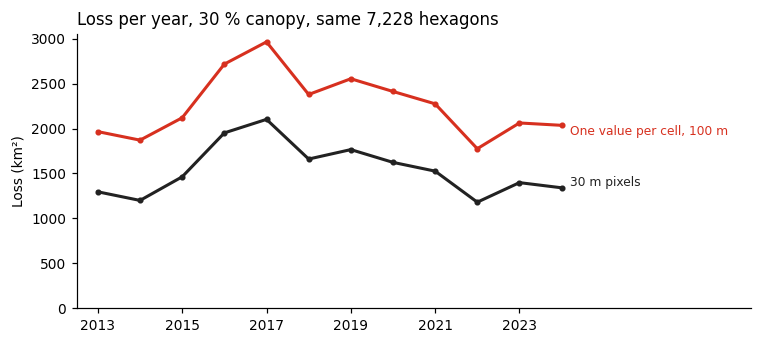

Area of the hexagons: 217,872 km²


,30 m pixels,"One value per cell, 100 m","One value per cell, 100 m: error (%)"
forest_2000,72909.0,78633.0,8.0
2013,1296.0,1966.0,52.0
2014,1200.0,1871.0,56.0
2015,1463.0,2120.0,45.0
2016,1952.0,2717.0,39.0
2017,2102.0,2964.0,41.0
2018,1661.0,2379.0,43.0
2019,1766.0,2554.0,45.0
2020,1624.0,2413.0,49.0
2021,1526.0,2275.0,49.0


In [3]:
hexes = A.hex_comparison()
national = hexes.groupby("source")[["forest_2000"] + YEARS].sum().T
national.columns = ["30 m pixels", "One value per cell, 100 m"]
for c in national.columns[1:]:
    national[f"{c}: error (%)"] = 100 * (national[c] / national["30 m pixels"] - 1)
national.round(1).to_csv(OUT / "01_national.csv")

fig, ax = plt.subplots(figsize=(7, 3.2))
for c, colour, style in (("30 m pixels", COLOURS["30 m pixels"], "-"), ("One value per cell, 100 m", COLOURS["One value per cell"], "-")):
    ax.plot(A.YEARS, national.loc[YEARS, c], color=colour, linestyle=style, marker="o", markersize=3, linewidth=2)
    ax.text(A.YEARS[-1] + 0.2, national.loc[YEARS[-1], c] + (-60 if "100" in c else 60), c, color=colour, fontsize=8, va="center")
ax.set_ylim(0, None)
ax.set_xlim(2012.5, 2028.5)
ax.set_xticks(range(2013, 2025, 2))
ax.set_ylabel("Loss (km²)")
ax.set_title("Loss per year, 30 % canopy, same 7,228 hexagons", loc="left")
plt.tight_layout(); plt.show()
print(f"Area of the hexagons: {A.hexagons_inside().to_crs(6933).area.sum() / 1e6:,.0f} km²")
national.round(0)

**Reading:**

* **One value per cell counts 39–56 % more loss than the 30 m pixels in every year**. The hexagons cover 217,872 km², 89 % of Guinea.
* **Forest in 2000 is 8 % too large.**
* The ups and downs from year to year are the same, so the trend is right, but every area is too large.

## 3 · One value per cell drawback

Earth Engine keeps each band at several resolutions (a pyramid). Read at 100 m, a band is summarised from its 30 m pixels by the band's pyramiding policy.

In [4]:
A.asset_check().round(1)

,Band,Pyramiding policy,Pixels with a value (%)
0,treecover2000,MEAN,100.0
1,lossyear,MODE,15.4


**Reading:** in the Hansen asset on Earth Engine, only lost pixels have a loss year: in the test area, 15 % of the 30 m pixels have one and the other 85 % are empty, not 0. At 100 m, the loss year of a cell is the most common value among its pixels, and empty pixels do not count. So **a cell with even a few lost pixels takes their loss year, and the whole cell counts as lost.** Canopy is summarised by its mean, which is why forest is only a little too large.

Filling the empty pixels with 0 before reading does not fix it: the most common value of most cells would then be "no loss", and loss would be counted too little, as with the majority rule (section 4).

## 4 · Testing in four test areas

Four areas of 0.5° × 0.5° (about 3,000 km² each): per-cell share and majority computed from the 30 m pixels on Earth Engine at 50 and 100 m, and one value per cell read as the deforestation notebook reads it. Error = area against the 30 m pixels.

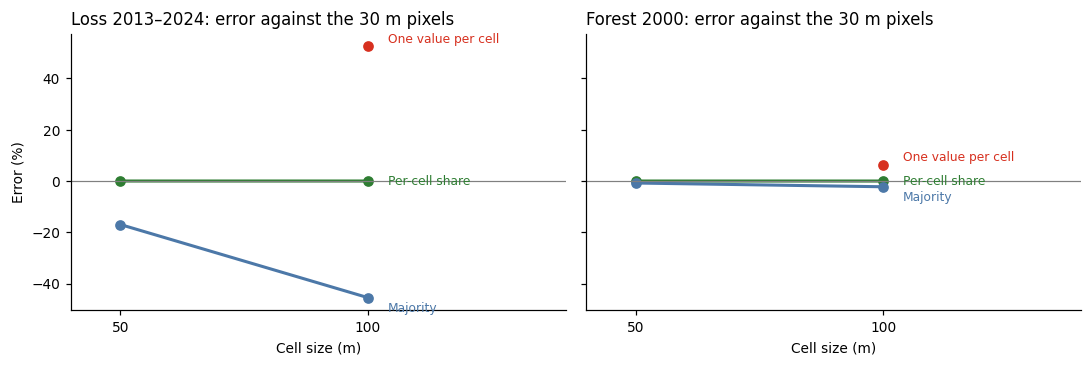

area                      Forest-savanna, east  \
method             cell                          
Majority           100 m                 -57.3   
                   50 m                  -24.2   
One value per cell 100 m                  88.1   
Per-cell share     100 m                   0.0   
                   50 m                    0.0   

area                      Forest-savanna, north-west (loss hotspot)  \
method             cell                                               
Majority           100 m                                      -28.5   
                   50 m                                       -10.8   
One value per cell 100 m                                       44.1   
Per-cell share     100 m                                        0.0   
                   50 m                                         0.0   

area                      Lowland forests, south-east  \
method             cell                                 
Majority           100 m                        -53.7   
                   50 m                         -19.6   
One value per cell 100 m                         53.3   
Per-cell share     100 m                          0.0   
                   50 m                           0.0   

area                      Montane forests (Fouta Djallon)  All four areas  
method             cell                                                    
Majority           100 m                            -30.1           -45.5  
                   50 m                             -11.6           -16.9  
One value per cell 100 m                             47.3            52.5  
Per-cell share     100 m                              0.0             0.0  
                   50 m                               0.0             0.0

In [5]:
test = pd.concat([A.test_area_sums(), A.single_value_test_area_sums()])
test["loss"] = test[YEARS].sum(axis=1)
truth = test[test.method == "30 m pixels"].set_index("area")
test = test[test.method != "30 m pixels"].copy()
for col in ("forest_2000", "loss"):
    test[f"{col} error (%)"] = 100 * (test[col] / test.area.map(truth[col]) - 1)
errors = test.pivot_table(index=["method", "cell"], columns="area", values="loss error (%)")
errors["All four areas"] = test.groupby(["method", "cell"]).loss.sum() / truth.loss.sum() * 100 - 100
forest_errors = test.groupby(["method", "cell"]).forest_2000.sum() / truth.forest_2000.sum() * 100 - 100
errors.round(1).to_csv(OUT / "01_test_area_loss_errors.csv")

SIZES = {"50 m": 50, "100 m": 100}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (values, title) in zip(axes, ((errors["All four areas"], "Loss 2013–2024"), (forest_errors, "Forest 2000"))):
    for method in ("Per-cell share", "Majority", "One value per cell"):
        v = values[method].sort_index(key=lambda idx: idx.map(SIZES))
        x = [SIZES[c] for c in v.index]
        ax.plot(x, v.values, marker="o", color=COLOURS[method], linewidth=2)
        ax.text(x[-1] + 4, v.values[-1] + {"Majority": -4, "One value per cell": 3}.get(method, 0), method, color=COLOURS[method], fontsize=8, va="center")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xticks([50, 100])
    ax.set_xlim(40, 140)
    ax.set_xlabel("Cell size (m)")
    ax.set_title(f"{title}: error against the 30 m pixels", loc="left")
axes[0].set_ylabel("Error (%)")
plt.tight_layout(); plt.show()
errors.round(1)

**Reading:**

* **The per-cell share gives the 30 m area at every cell size** (error 0.0 to 0.1 %), for forest and for loss.
* **The majority rule counts too little loss: −17 % at 50 m, −46 % at 100 m.** Clearings are smaller than the cells, so few cells are more than half cleared in one year.
* **One value per cell counts about half too much**, +52 % at 100 m.
* So what matters is not the cell size but how a cell holds its 30 m pixels. A cell that counts whole is wrong one way or the other; even at 50 m the majority rule misses a sixth of the loss.

## 5 · By hexagon

One value per cell at 100 m against the 30 m pixels in each hexagon (loss 2013–2024; hexagons with at least 0.5 km² of loss). Summing the cells into hexagons does not remove the error: each hexagon's total is the sum of its cells. The per-cell shares summed into the same hexagons follow.

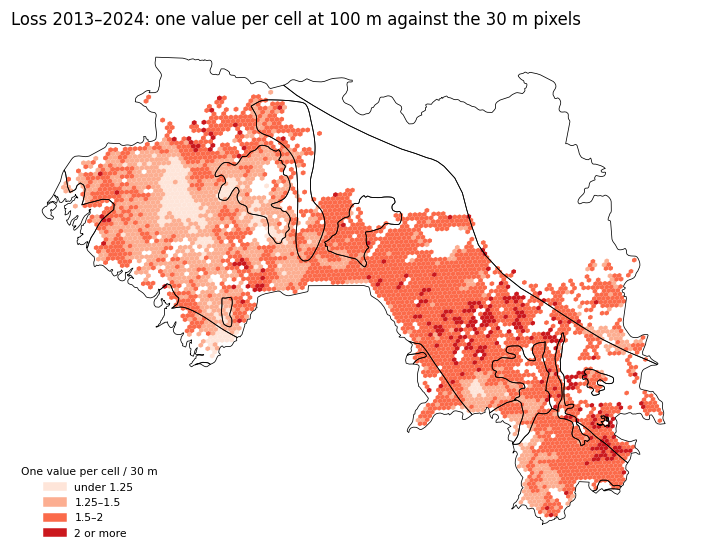

,Hexagons,Share of the 30 m loss (%),"One value per cell, 100 m / 30 m (median)","One value per cell, 100 m / 30 m (total)"
"Loss 2013–2024, % of the forest of 2000",,,,
under 5 %,129,0.54,1.87,1.87
5–10 %,600,4.22,1.83,1.80
10–20 %,1218,14.88,1.74,1.72
20–40 %,1221,30.33,1.57,1.53
40 % or more,1042,50.03,1.34,1.30


In [6]:
import geopandas as gpd

wide = hexes.pivot_table(index="h3_id", columns="source", values=YEARS, aggfunc="sum")
loss = pd.DataFrame({s: wide.xs(s, axis=1, level=1).sum(axis=1) for s in hexes.source.unique()})
forest = hexes.pivot_table(index="h3_id", columns="source", values="forest_2000")
loss = loss[loss["30 m pixels"] >= 0.5]
ratio = loss["One value per cell, 100 m"] / loss["30 m pixels"]
density = 100 * loss["30 m pixels"] / forest.loc[loss.index, "30 m pixels"]          # % of the 2000 forest lost

bins = pd.cut(density, [0, 5, 10, 20, 40, 100], labels=["under 5 %", "5–10 %", "10–20 %", "20–40 %", "40 % or more"])
by_density = pd.DataFrame({"Hexagons": ratio.groupby(bins, observed=False).size(),
                           "Share of the 30 m loss (%)": 100 * loss["30 m pixels"].groupby(bins, observed=False).sum() / loss["30 m pixels"].sum(),
                           "One value per cell, 100 m / 30 m (median)": ratio.groupby(bins, observed=False).median(),
                           "One value per cell, 100 m / 30 m (total)": loss["One value per cell, 100 m"].groupby(bins, observed=False).sum()
                                                            / loss["30 m pixels"].groupby(bins, observed=False).sum()})
by_density.index.name = "Loss 2013–2024, % of the forest of 2000"
by_density.round(2).to_csv(OUT / "01_hexagon_error_by_loss_density.csv")

polygons = A.hexagons_inside().set_index("h3_id").loc[ratio.index]
polygons["ratio"] = ratio
BANDS = {"under 1.25": "#fee5d9", "1.25–1.5": "#fcae91", "1.5–2": "#fb6a4a", "2 or more": "#cb181d"}
polygons["band"] = pd.cut(polygons.ratio, [0, 1.25, 1.5, 2, np.inf], labels=list(BANDS), right=False)
eco = gpd.read_file(A.DD.STUDIES / "output_datasets" / "ecoregions_guinea.gpkg", layer="ecoregions_guinea").to_crs(4326)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for band, colour in BANDS.items():
    polygons[polygons.band == band].plot(ax=ax, color=colour, linewidth=0)
eco.boundary.plot(ax=ax, color="black", linewidth=0.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=b) for b, c in BANDS.items()], title="One value per cell / 30 m", loc="lower left", frameon=False, fontsize=7, title_fontsize=7)
ax.set_axis_off()
ax.set_title("Loss 2013–2024: one value per cell at 100 m against the 30 m pixels", loc="left")
plt.tight_layout(); plt.show()
by_density.round(2)

**Reading:**

* **Every hexagon with loss is overcounted, most where loss is sparse**: 1.8–1.9 times in hexagons that lost under 10 % of their forest, 1.3 times where they lost 40 % or more. Sparse loss means more cells with only a few lost pixels, each counted whole.
* **Hexagons do not fix it**: a hexagon's total is the sum of its cells, and carries their error.

In [7]:
# The per-cell shares summed into the same hexagons, against Hansen's 30 m tiles summed into them
# (every 30 m pixel to the hexagon holding its centre; notebook 02)
loss_cols = [f"loss_{y}" for y in A.YEARS]
from_shares = R.coarser(R.by_100m("h3"), 6)[loss_cols].sum(axis=1)
from_pixels = R.coarser(R.by_30m("h3"), 6)[loss_cols].sum(axis=1)
same = ratio.index.intersection(from_shares.index)
share_ratio = from_shares[same] / from_pixels[same]
compare = pd.DataFrame({
    "Hexagons": share_ratio.groupby(bins[same], observed=False).size(),
    "One value per cell / 30 m (median)": ratio[same].groupby(bins[same], observed=False).median(),
    "Per-cell share / 30 m (median)": share_ratio.groupby(bins[same], observed=False).median(),
    "Per-cell share: error, 95th percentile (%)": (100 * (share_ratio - 1).abs()).groupby(bins[same], observed=False).quantile(0.95)})
compare.loc["All"] = [len(same), ratio[same].median(), share_ratio.median(), (100 * (share_ratio - 1).abs()).quantile(0.95)]
compare.index.name = "Loss 2013–2024, % of the forest of 2000"
compare.round(3).to_csv(OUT / "01_hexagon_shares.csv")
print(f"{len(same):,} of the {len(ratio):,} hexagons above; total loss from the shares / 30 m: {from_shares[same].sum() / from_pixels[same].sum():.4f}")
compare.round(3)

4,210 of the 4,210 hexagons above; total loss from the shares / 30 m: 0.9999


,Hexagons,One value per cell / 30 m (median),Per-cell share / 30 m (median),"Per-cell share: error, 95th percentile (%)"
"Loss 2013–2024, % of the forest of 2000",,,,
under 5 %,129.0,1.865,1.0,2.048
5–10 %,600.0,1.826,1.0,1.431
10–20 %,1218.0,1.736,1.0,1.112
20–40 %,1221.0,1.568,1.0,0.888
40 % or more,1042.0,1.341,1.0,0.616
All,4210.0,1.608,1.0,1.093


**Reading:**

* **Summed from the per-cell shares, every hexagon gets its 30 m loss**: the median ratio is 1.00 in every class, against 1.34–1.87 for one value per cell, and the total over the 4,210 hexagons is within 0.01 %.
* **95 % of the hexagons are within 1.1 %**, 2 % where loss is sparse. What is left is the border of each hexagon: a 100 m cell goes whole to the hexagon holding its centre, its 30 m pixels each to their own.

## 6 · The shares on the platform's grid

Read from Earth Engine as the platform reads them (`getDownloadURL`, 100 m, EPSG:4326) onto the grid of section 1, with `data_100m_tools/fetch.py`, and saved in the shared store:

| Layer | Per cell | Bands |
|---|---|---|
| `hansen_shares` | The share that was forest in 2000 (canopy ≥ 30 %, as the platform), that is land, and that was forest and lost in each year | forest2000, land, loss_2001 … loss_2024 |

The same store holds Esri land cover 2017–2025 for the land-use work; it is not used here.

Shares are stored as whole percentages, computed as the platform computes them (`hansen_shares_image`, 26 October 2026). The canopy rule follows the platform (≥ 30 %); stage 1 used > 30 %, a difference of 0.05 % of the forest and 0.04 % of the loss (canopy of exactly 30 %, tested on 5,000 km² of forest-savanna).

In [8]:
area_ha = G.cell_area_ha()


def km2(share):
    return float((share * area_ha).sum() / 100)


def coarse(values, factor=10):
    # Mean over blocks of factor x factor cells (1 km), for drawing maps of the whole country.
    grid = G.to_grid(values.astype("float32"))
    h, w = (grid.shape[0] // factor) * factor, (grid.shape[1] // factor) * factor
    with np.errstate(invalid="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)               # blocks wholly outside Guinea
        return np.nanmean(grid[:h, :w].reshape(h // factor, factor, w // factor, factor), axis=(1, 3))

National forest and loss from the shares (share × cell area, summed over the cells inside Guinea), against the platform's own run with the same shares (deforestation analysis of 26 October 2026, job 17, read from its API) and against the 30 m pixels counted in stage 1 (canopy > 30 %, stage-1 boundary).

In [9]:
H = G.read_layer("hansen_shares", scaled=True)
YEARS = list(range(2013, 2025))
platform = dict(zip(YEARS, [1466, 1331, 1623, 2170, 2320, 1834, 1945, 1791, 1681, 1305, 1548, 1474]))   # km², job 17
truth = pd.read_parquet(REPO / "studies" / "output_datasets" / "hansen_loss_by_h3_res6_polygon_year.parquet")
truth = truth.groupby("year").forest2000_gt30_km2.sum()
hansen = pd.DataFrame({"100 m shares": {y: km2(H[f"loss_{y}"]) for y in YEARS},
                       "Platform (job 17)": platform, "30 m pixels (stage 1)": truth.loc[YEARS]})
hansen["vs platform (%)"] = 100 * (hansen["100 m shares"] / hansen["Platform (job 17)"] - 1)
hansen["vs 30 m pixels (%)"] = 100 * (hansen["100 m shares"] / hansen["30 m pixels (stage 1)"] - 1)
hansen.index.name = "Loss (km²)"
hansen.round(1).to_csv(OUT / "01_hansen_loss_check.csv")
print(f"Forest 2000: {km2(H['forest2000']):,.0f} km²; land: {km2(H['land']):,.0f} km² "
      f"(platform's land: 245,423 km²; forest 2001 = forest 2000 - loss 2001 = {km2(H['forest2000']) - km2(H['loss_2001']):,.0f} km², platform 81,670)")
hansen.round(1)

Forest 2000: 81,856 km²; land: 245,424 km² (platform's land: 245,423 km²; forest 2001 = forest 2000 - loss 2001 = 81,669 km², platform 81,670)


,100 m shares,Platform (job 17),30 m pixels (stage 1),vs platform (%),vs 30 m pixels (%)
Loss (km²),,,,,
2013,1465.8,1466,1473.4,-0.0,-0.5
2014,1330.8,1331,1332.5,-0.0,-0.1
2015,1622.4,1623,1627.6,-0.0,-0.3
2016,2169.8,2170,2172.5,-0.0,-0.1
2017,2319.5,2320,2323.5,-0.0,-0.2
2018,1833.7,1834,1831.4,-0.0,0.1
2019,1945.1,1945,1945.0,0.0,0.0
2020,1791.1,1791,1793.9,0.0,-0.2
2021,1681.2,1681,1680.8,0.0,0.0


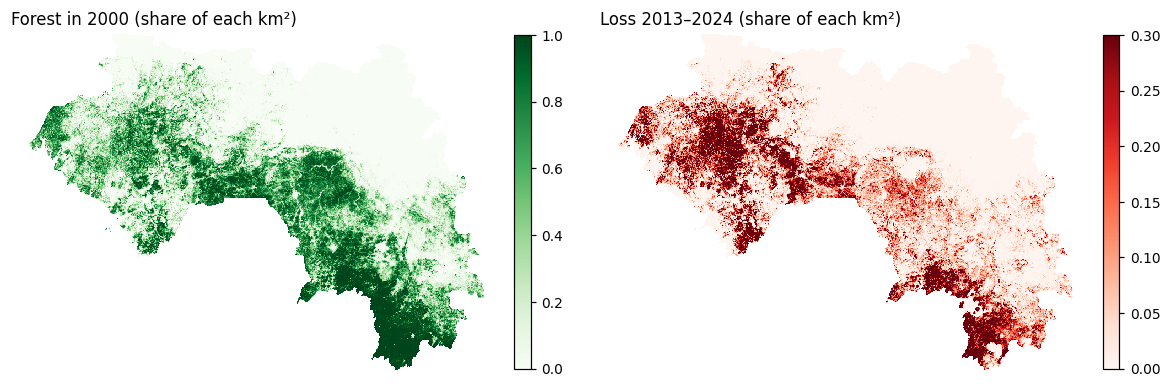

In [10]:
loss_recent = sum(H[f"loss_{y}"] for y in YEARS)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (values, title, cmap) in zip(axes, ((H["forest2000"], "Forest in 2000 (share of each km²)", "Greens"),
                                           (loss_recent, "Loss 2013–2024 (share of each km²)", "Reds"))):
    im = ax.imshow(coarse(values), cmap=cmap, vmin=0, vmax=1 if "Forest" in title else 0.3, interpolation="nearest")
    ax.set_title(title, loc="left")
    ax.set_axis_off()
    plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout(); plt.show()

**Reading:**

* **The 100 m shares give the platform's loss to the hectare in every year** (0.0 %), and the 30 m pixels counted in stage 1 within 0.5 %. The small gap is the boundary (stage 1 used another outline) and the canopy rule (≥ against > 30 %).
* **Land (245,424 km²) and forest are the platform's too**: its forest of 2001 is the forest of 2000 less the loss of 2001.
* So the deforestation work at 100 m starts from the same areas as the platform.

## 7 · Would a finer grid or hexagons help?

Errors against Hansen's 30 m pixels: loss 2013–2024 and forest 2000 in the four test areas (section 4), and per year nationally on the same hexagons (section 2). The platform's 100 m run peaks at about 9 GB of its worker's 10 GB.

| Option | Loss | Forest 2000 | For the model | On the platform's server | Verdict |
|---|---|---|---|---|---|
| One value per cell, 100 m | +52 % (+39 to +56 % per year nationally) | +6 % (+8 % nationally) | Finer distances and edges | Runs now | **Counts about half too much loss: a finer grid alone does not help** |
| Majority, 50 / 100 m | −17 / −46 % | −1 / −2 % | Most loss not counted | 50 m: four times the cells, does not fit | Wrong the other way, even at 50 m |
| **Per-cell share, 100 m** | **0.0 %** | **0.0 %** | Finer distances and edges | Runs now (the areas already do) | **Recommended** |
| 30 m / 10 m | Exact / no more than 30 m | Exact | Finest | 11 / 100 times the cells | Not possible; Hansen has nothing below 30 m |
| Hexagons | The error of their cells (1.3–1.9 times) | Same | Not a modelling grid: distances and moving windows need a raster | Small | **For reporting**, summing per-cell shares (section 5) |

## 8 · What this means

* **At 100 m, areas come from per-cell shares**: for each 100 m cell, Earth Engine gives the share of its 30 m pixels that are forest (canopy above 30 %) and that were lost in each year, as section 4 computes them. Areas are the share times the cell area. The platform computes its forest and loss areas this way (since 26 October 2026), and the 100 m work here does the same, on the same grid: its areas are the platform's to the hectare (section 6).
* **The model still needs each cell to be lost or not for training.** The per-year majority rule leaves out most of the loss. The platform uses a cumulative rule (a cell is lost in the year its remaining forest share falls below half); notebook 04 tests it against alternatives. Areas come from the shares whatever the rule.
* **Hexagons stay for reporting**, as stage 1 used them, summed from the shares. Notebook 02 checks every unit the platform reports.